In [ ]:
from pydantic import BaseModel

# langraph - State, Nodes, Edges, LLM

# State object
class SupportTicket(BaseModel):
    user_query : str 
    query_domain : str = None
    context : str = None
    response : str = None
    nodes_ran : list = []

In [12]:
from langchain_ollama import ChatOllama
llm = ChatOllama(model="llama3.2:3b")

In [44]:
def classifier_node(state : SupportTicket):
    state.nodes_ran.append("classifier_node")
    prompt = f"""
    categorise the user query into one of the 3 category
    Category Names:
    1. Billing
    2. Shiiping
    3. Technical

    user query : {state.user_query}  

    RETURN ONLY ONE CATEGORY NAME BASED ON THE USER QUERY, NOTHING ELSE
    """
    response = llm.invoke(prompt)
    state.query_domain = response.content
    return state
    

In [14]:
def billing_node(state:SupportTicket):
    state.nodes_ran.append("billing_node")
    data = """
    Some Billing data fetched from DB based on the user query
    customer invoice is pending
         Amount due : 5$
         Due Date : 20 June
    """

    state.context = data

    return state

In [15]:
def shipping_node(state:SupportTicket):
    state.nodes_ran.append("shipping_node")
    data = """
    Some Shipping data fetched from DB based on the user query
    Packate is in transit,
        Expected delivery : Tomorrow
    """

    state.context = data

    return state

In [16]:
def technical_node(state:SupportTicket):
    state.nodes_ran.append("technical_node")
    data = """
    Some Technical data fetched from DB based on the user query
    Common troublshootings
        1. Restart application
        2. clear cache
        3. Re-Login
    """

    state.context = data

    return state

In [17]:
def responseder_node(state: SupportTicket):
    state.nodes_ran.append("responseder_node")
    prompt = f"""
    You are a helpful customer support agent, answer user query based on the context given

    user query : {state.user_query}

    context : {state.context}

    generate a helpful response
    """

    response = llm.invoke(prompt)
    state.response = response
    return state
    

In [38]:
def router(state: SupportTicket):
    domain = state.query_domain
    if "bill" in domain:
        return "biller"
    elif "tech" in domain:
        return "technical"
    return "shipping"
    

In [45]:
from langgraph.graph import StateGraph, END

# create graph
graphBuilder = StateGraph(SupportTicket)
#nodes
graphBuilder.add_node("classifierNode", classifier_node)
graphBuilder.add_node("billingNode", billing_node)
graphBuilder.add_node("shippingNode", shipping_node)
graphBuilder.add_node("technicalNode", technical_node)
graphBuilder.add_node("responsederNode", responseder_node)

## Set entry point
graphBuilder.set_entry_point("classifierNode")

# connect nodes using edges
graphBuilder.add_conditional_edges(
    "classifierNode", 
    router, 
    {
        "biller" : "billingNode",
        "technical" : "technicalNode",
        "shipping" : "shippingNode"
    })

graphBuilder.add_edge("billingNode", "responsederNode")
graphBuilder.add_edge("shippingNode", "responsederNode")
graphBuilder.add_edge("technicalNode", "responsederNode")
graphBuilder.add_edge("responsederNode", END)

#compile
graph = graphBuilder.compile()
                                   

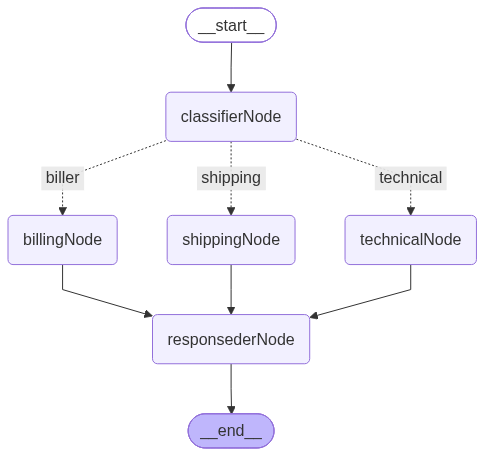

In [40]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [47]:
state = SupportTicket(user_query = "where is my shipping?")
result = graph.invoke(state)
print(result["nodes_ran"])
print(result["response"].content)
                      

['classifier_node', 'shipping_node', 'responseder_node']
"Hello!

Thank you for reaching out to us about your shipping status. We're happy to help you track the progress of your order.

According to our records, we've confirmed that your package has shipped and is currently in transit with our carrier. The expected delivery date is tomorrow, which means it should arrive soon!

Here are the details of your shipment:

* Order Number: [insert order number]
* Tracking Number: [insert tracking number]
* Expected Delivery Date: Tomorrow
* Shipping Carrier: [insert shipping carrier]

If you'd like to get real-time updates on the status of your package, we recommend checking the tracking information on our website or contacting our customer service team directly. We're here to help and want to ensure that you receive your order in a timely manner.

Is there anything else I can assist you with today?
